In [1]:
import sys

print("Python version:", sys.version)
print("Project environment is working!")

Python version: 3.10.0 (tags/v3.10.0:b494f59, Oct  4 2021, 19:00:18) [MSC v.1929 64 bit (AMD64)]
Project environment is working!


In [2]:
import os

wesad_path = "../data/raw/WESAD"

print("WESAD folder exists:", os.path.exists(wesad_path))

if os.path.exists(wesad_path):
    print("\nFiles and folders inside WESAD:")
    for item in os.listdir(wesad_path):
        print(item)

WESAD folder exists: True

Files and folders inside WESAD:
S10
S11
S13
S14
S15
S16
S17
S2
S3
S4
S5
S6
S7
S8
S9
wesad_readme.pdf


In [3]:
import os

subject_path = "../data/raw/WESAD/S2"

print("S2 folder exists:", os.path.exists(subject_path))

if os.path.exists(subject_path):
    print("\nFiles inside S2:")
    for item in os.listdir(subject_path):
        print(item)

S2 folder exists: True

Files inside S2:
S2.pkl
S2_E4_Data.zip
S2_quest.csv
S2_readme.txt
S2_respiban.txt


In [4]:
import os

subject_path = "../data/raw/WESAD/S2"

print("S2 folder exists:", os.path.exists(subject_path))

if os.path.exists(subject_path):
    print("\nFiles inside S2:")
    for item in os.listdir(subject_path):
        print(item)

S2 folder exists: True

Files inside S2:
S2.pkl
S2_E4_Data.zip
S2_quest.csv
S2_readme.txt
S2_respiban.txt


In [7]:
import pickle

file_path = "../data/raw/WESAD/S2/S2.pkl"

with open(file_path, "rb") as file:
    data = pickle.load(file, encoding="latin1")

print("Data loaded successfully!")
print("Data type:", type(data))

Data loaded successfully!
Data type: <class 'dict'>


In [8]:
print("Keys in the dataset:")
print(data.keys())

Keys in the dataset:
dict_keys(['signal', 'label', 'subject'])


In [9]:
print("Signal types:")
print(data["signal"].keys())

Signal types:
dict_keys(['chest', 'wrist'])


In [10]:
print("Chest sensor types:")
print(data["signal"]["chest"].keys())

Chest sensor types:
dict_keys(['ACC', 'ECG', 'EMG', 'EDA', 'Temp', 'Resp'])


In [11]:
print("Wrist sensor types:")
print(data["signal"]["wrist"].keys())

Wrist sensor types:
dict_keys(['ACC', 'BVP', 'EDA', 'TEMP'])


In [12]:
print("Chest sensor data shapes:")

for sensor, values in data["signal"]["chest"].items():
    print(sensor, values.shape)

print("\nWrist sensor data shapes:")

for sensor, values in data["signal"]["wrist"].items():
    print(sensor, values.shape)

Chest sensor data shapes:
ACC (4255300, 3)
ECG (4255300, 1)
EMG (4255300, 1)
EDA (4255300, 1)
Temp (4255300, 1)
Resp (4255300, 1)

Wrist sensor data shapes:
ACC (194528, 3)
BVP (389056, 1)
EDA (24316, 1)
TEMP (24316, 1)


In [13]:
print("Label shape:")
print(data["label"].shape)

print("\nUnique labels:")
print(set(data["label"]))

Label shape:
(4255300,)

Unique labels:
{0, 1, 2, 3, 4, 6, 7}


In [14]:
print("Chest sensor data shapes:")

for sensor, values in data["signal"]["chest"].items():
    print(sensor, values.shape)

print("\nWrist sensor data shapes:")

for sensor, values in data["signal"]["wrist"].items():
    print(sensor, values.shape)

Chest sensor data shapes:
ACC (4255300, 3)
ECG (4255300, 1)
EMG (4255300, 1)
EDA (4255300, 1)
Temp (4255300, 1)
Resp (4255300, 1)

Wrist sensor data shapes:
ACC (194528, 3)
BVP (389056, 1)
EDA (24316, 1)
TEMP (24316, 1)


In [15]:
print("Label shape:")
print(data["label"].shape)

print("\nUnique labels:")
print(sorted(set(data["label"])))

Label shape:
(4255300,)

Unique labels:
[0, 1, 2, 3, 4, 6, 7]


In [16]:
print(data["label"][:50])

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [17]:
print("Subject:", data["subject"])

print("\nLabel counts:")
import numpy as np

labels, counts = np.unique(data["label"], return_counts=True)

for label, count in zip(labels, counts):
    print(f"Label {label}: {count} samples")

Subject: S2

Label counts:
Label 0: 2142701 samples
Label 1: 800800 samples
Label 2: 430500 samples
Label 3: 253400 samples
Label 4: 537599 samples
Label 6: 45500 samples
Label 7: 44800 samples


In [18]:
import matplotlib.pyplot as plt

eda = data["signal"]["chest"]["EDA"].flatten()

# Plot only the first 5000 samples
plt.figure(figsize=(12, 4))
plt.plot(eda[:5000])

plt.title("Chest EDA Signal - Subject S2")
plt.xlabel("Sample")
plt.ylabel("EDA")
plt.grid(True)
plt.show()

ModuleNotFoundError: No module named 'matplotlib'

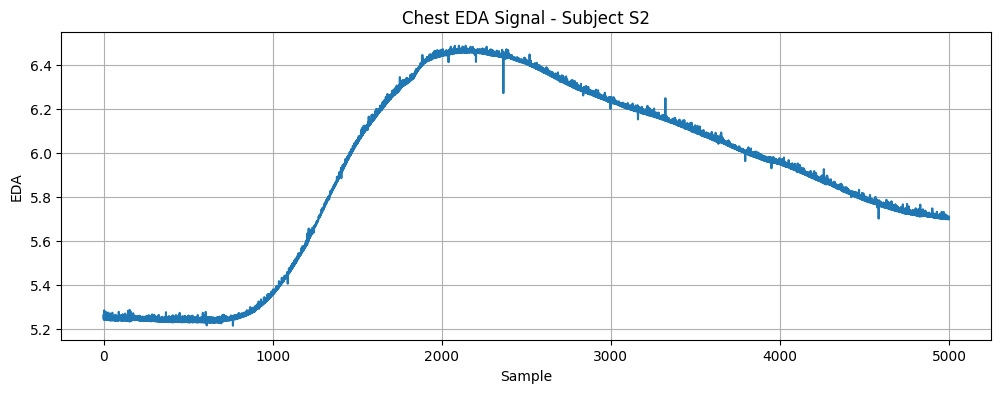

In [19]:
import matplotlib.pyplot as plt

eda = data["signal"]["chest"]["EDA"].flatten()

plt.figure(figsize=(12, 4))
plt.plot(eda[:5000])

plt.title("Chest EDA Signal - Subject S2")
plt.xlabel("Sample")
plt.ylabel("EDA")
plt.grid(True)
plt.show()

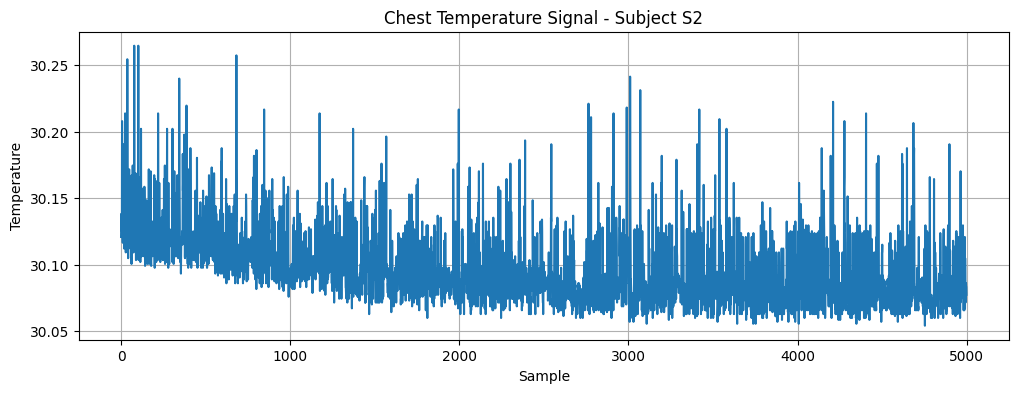

In [20]:
temp = data["signal"]["chest"]["Temp"].flatten()

plt.figure(figsize=(12, 4))
plt.plot(temp[:5000])

plt.title("Chest Temperature Signal - Subject S2")
plt.xlabel("Sample")
plt.ylabel("Temperature")
plt.grid(True)
plt.show()

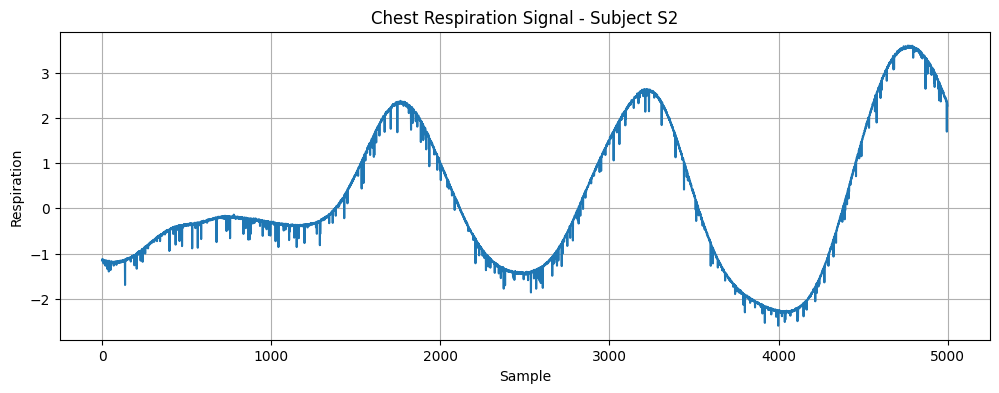

In [21]:
resp = data["signal"]["chest"]["Resp"].flatten()

plt.figure(figsize=(12, 4))
plt.plot(resp[:5000])

plt.title("Chest Respiration Signal - Subject S2")
plt.xlabel("Sample")
plt.ylabel("Respiration")
plt.grid(True)
plt.show()

In [22]:
import pandas as pd

file_path = "../data/processed/wesad_features.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

Dataset loaded successfully!
Shape: (8679, 18)

Columns:
['subject', 'label', 'ecg_mean', 'ecg_std', 'ecg_min', 'ecg_max', 'eda_mean', 'eda_std', 'eda_min', 'eda_max', 'temp_mean', 'temp_std', 'temp_min', 'temp_max', 'resp_mean', 'resp_std', 'resp_min', 'resp_max']


In [23]:
df.head()

,subject,label,ecg_mean,ecg_std,ecg_min,ecg_max,eda_mean,eda_std,eda_min,eda_max,temp_mean,temp_std,temp_min,temp_max,resp_mean,resp_std,resp_min,resp_max
0,S10,0,0.007264,0.278695,-1.333694,1.473129,0.723950,0.013708,0.509644,0.815964,33.737595,0.022834,33.659485,33.868835,-0.271944,1.473868,-3.038025,2.793884
1,S10,0,-0.000109,0.144062,-0.596603,0.739517,0.725080,0.014060,0.416183,0.827026,33.762050,0.024988,33.680695,33.908386,-0.025674,2.465345,-4.389954,5.418396
2,S10,0,0.002817,0.140031,-0.574036,0.711548,0.728110,0.013667,0.639343,0.835800,33.798260,0.024068,33.721620,33.932680,0.286431,1.536638,-2.635193,2.818298
3,S10,0,0.000188,0.150107,-0.762772,0.779617,0.730447,0.013367,0.642395,0.808716,33.793186,0.023917,33.723114,33.923553,-0.117829,1.897925,-5.169678,4.104614
4,S10,0,0.002531,0.159638,-0.612305,0.936081,0.731428,0.013212,0.609589,0.814438,33.784560,0.023108,33.667084,33.909880,0.128096,1.710412,-3.773499,3.538513


In [24]:
print("Label distribution:")
print(df["label"].value_counts().sort_index())

Label distribution:
label
0    3939
1    1761
2    1000
3     559
4    1177
5      78
6      82
7      83
Name: count, dtype: int64


In [25]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
subject      0
label        0
ecg_mean     0
ecg_std      0
ecg_min      0
ecg_max      0
eda_mean     0
eda_std      0
eda_min      0
eda_max      0
temp_mean    0
temp_std     0
temp_min     0
temp_max     0
resp_mean    0
resp_std     0
resp_min     0
resp_max     0
dtype: int64


In [26]:
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))
print("Subjects:", df["subject"].unique())

Number of rows: 8679
Number of columns: 18
Subjects: ['S10' 'S11' 'S13' 'S14' 'S15' 'S16' 'S17' 'S2' 'S3' 'S4' 'S5' 'S6' 'S7'
 'S8' 'S9']


In [27]:
import numpy as np

from privacy.differential_privacy import (
    privatize_parameters
)

# Create example model parameters
coef = np.array([[1.0, 2.0, 3.0]])

intercept = np.array([0.5])

parameters = (
    coef,
    intercept
)

# Apply privacy
protected = privatize_parameters(
    parameters,
    max_norm=1.0,
    noise_scale=0.05
)

print("Original coefficients:")
print(coef)

print("\nProtected coefficients:")
print(protected[0])

print("\nOriginal intercept:")
print(intercept)

print("\nProtected intercept:")
print(protected[1])

ModuleNotFoundError: No module named 'privacy'

In [28]:
import sys
import os

project_root = os.path.abspath("..")

if project_root not in sys.path:
    sys.path.insert(0, project_root)

print("Project root:", project_root)

Project root: c:\Users\jupel\OneDrive\Desktop\PE-FedHealth


In [29]:
from privacy.differential_privacy import privatize_parameters

print("Privacy module imported successfully!")

Privacy module imported successfully!


In [30]:
import numpy as np

coef = np.array([[1.0, 2.0, 3.0]])
intercept = np.array([0.5])

parameters = (
    coef,
    intercept
)

protected = privatize_parameters(
    parameters,
    max_norm=1.0,
    noise_scale=0.05
)

print("Original coefficients:")
print(coef)

print("\nProtected coefficients:")
print(protected[0])

print("\nOriginal intercept:")
print(intercept)

print("\nProtected intercept:")
print(protected[1])

Original coefficients:
[[1. 2. 3.]]

Protected coefficients:
[[0.27652071 0.56208816 0.85569227]]

Original intercept:
[0.5]

Protected intercept:
[0.11733291]
